In [5]:
import pandas as pd
import os

In [1]:
import pandas as pd, glob
d = pd.concat([pd.read_parquet(f) for f in sorted(glob.glob("processed/delays_*.parquet"))])
d["run"] = d["trip_uid"].str.split("_").str[0] + "|" + d["route_id"].astype(str) + "|" + d["direction_id"].astype(str)
d["n"] = d.groupby("trip_uid")["stop_id"].transform("size")

n_uid = d.groupby("run")["trip_uid"].nunique()
multi = n_uid[n_uid > 1].index
print("runs with >2 trip_uids:", (n_uid > 2).sum())

m = d[d["run"].isin(multi)]
prim = (m.sort_values(["n", "trip_id"], ascending=[False, False])
          .drop_duplicates("run")[["run", "trip_uid"]].rename(columns={"trip_uid": "primary"}))
m = m.merge(prim, on="run")
short, long_ = m[m["trip_uid"] != m["primary"]], m[m["trip_uid"] == m["primary"]]
j = short.merge(long_[["run", "stop_id", "event_sec"]], on=["run", "stop_id"], how="left", suffixes=("", "_long"))

print("short-trip stops also present in the longer trip:", j["event_sec_long"].notna().mean().round(3))
print((j["event_sec"] - j["event_sec_long"]).describe(percentiles=[.05, .5, .95]))

runs with >2 trip_uids: 6
short-trip stops also present in the longer trip: 0.799
count    18143.000000
mean        66.867662
std        918.056242
min      -3468.000000
5%        -593.000000
50%          2.000000
95%        751.000000
max      19607.000000
dtype: float64


In [2]:
import zipfile
z = zipfile.ZipFile("gtfs_archive/2023-12-14_536e8ccb.zip")
tr = pd.read_csv(z.open("trips.txt"), dtype=str)
t = pd.read_parquet("processed/delays_2024-01-03.parquet").drop_duplicates("trip_uid")
for r in ["W", "7X", "Z", "FX", "SS"]:
    print(r, "realtime:", t.loc[t["route_id"] == r, "trip_id"].head(3).tolist())
    print(r, "static:  ", tr.loc[tr["route_id"] == r, ["trip_id", "service_id"]].head(3).values.tolist())

W realtime: ['037300_W..S', '039600_W..S', '039615_W..S']
W static:   [['BFA23GEN-N098-Weekday-00_037300_N..S72R', 'Weekday'], ['BFA23GEN-N098-Weekday-00_039300_N..S72R', 'Weekday'], ['BFA23GEN-N098-Weekday-00_040300_N..S72R', 'Weekday']]
7X realtime: ['037500_7X..S', '038300_7X..S', '038800_7X..S']
7X static:   [['L0S1-7-1064-S02_037500_7..S98X001', 'Weekday'], ['L0S1-7-1064-S02_038300_7..S98X001', 'Weekday'], ['L0S1-7-1064-S02_038800_7..S98X001', 'Weekday']]
Z realtime: ['044000_Z..S', '044100_Z..S', '045250_Z..S']
Z static:   [['BFA23GEN-J054-Weekday-00_044100_J..S26R', 'Weekday'], ['BFA23GEN-J054-Weekday-00_045250_J..S26R', 'Weekday'], ['BFA23GEN-J054-Weekday-00_046250_J..S26R', 'Weekday']]
FX realtime: ['043000_FX..N', '043033_FX..N', '045308_FX..N']
FX static:   [['L0S1-F-1077-S04_042600_F..N72X003', 'Weekday'], ['L0S1-F-1077-S04_044750_F..N72X003', 'Weekday'], ['L0S1-F-1077-S04_098650_F..S72X004', 'Weekday']]
SS realtime: ['037500_SS..N', '039000_SS..N', '040500_SS..N']
SS stati

In [8]:
import pandas as pd, glob
d = pd.concat([pd.read_parquet(f) for f in sorted(glob.glob("processed/delays_*.parquet"))])
m = d[d["stop_matched"] & ~d["secondary_record"]].copy()

trip_med = m.groupby("trip_uid")["delay_s"].transform("median")
m["hour"] = (m["event_sec"] % 86400) // 3600
m["flag_trip"] = (trip_med < -600) | (trip_med > 3600)     # whole trip far from schedule
m["flag_stop"] = ~m["delay_s"].between(-1800, 7200)         # implausible single stop
m["overnight"] = m["hour"] < 4

keep = ~m["flag_trip"] & ~m["flag_stop"]
print("kept:", keep.mean().round(4))
print("dropped stops by reason:", m["flag_trip"].mean().round(4), m["flag_stop"].mean().round(4))

kept: 0.9857
dropped stops by reason: 0.0141 0.0052


In [4]:
import pandas as pd
t = pd.read_parquet("processed/delays_2024-01-03.parquet").drop_duplicates("trip_uid")
print(t.groupby("route_id")["trip_matched"].agg(["mean", "size"]).sort_values("mean").head(10).round(2))
print(t["secondary_record"].mean())

          mean  size
route_id            
SS        0.00    40
FX        0.75     4
FS        0.84   190
SI        0.84   165
H         0.84   167
A         0.85   379
M         0.88   271
J         0.88   288
R         0.89   301
D         0.90   336
0.017237494366831908


In [11]:
file_path = 'subway_files'
dfs = {}
for file in os.listdir(file_path):
    temp = file[file.find('nyc_')+4:]
    df_name = temp[:temp.find("_")]
    df_name+= "trips" if "trips" in temp else "stop_times"
    dfs[df_name] = pd.read_csv(os.path.join(file_path, file))
    print(dfs[df_name].head())

             trip_uid         trip_id route_id  direction_id  start_time  \
0  1704344460_4..N01R  030100_4..N01R        4             0  1704344460   
1  1704344490_3..S01R  030150_3..S01R        3             1  1704344490   
2     1704344700_7..N     030500_7..N        7             0  1704344700   
3  1704344730_6..S01R  030550_6..S01R        6             1  1704344730   
4  1704344760_2..N08R  030600_2..N08R        2             0  1704344760   

         vehicle_id  last_observed   marked_past  num_updates  \
0  04 0501  NLT/WDL     1704366836  1.704367e+09          628   
1  03 0501+ 148/NLT     1704366570  1.704367e+09          602   
2   07 0505 34H/MST     1704364991  1.704365e+09          410   
3  06 0505+ PEL/BBR     1704366296  1.704366e+09          544   
4  02 0506  FLA/241     1704369071  1.704369e+09          822   

   num_schedule_changes  num_schedule_rewrites         day  
0                     0                      0  2024-01-04  
1                     0       

In [30]:
import pandas as pd
import numpy as np

DAY = "2024-01-03"

st    = pd.read_csv(f"/home/ollie/projects/UC/RiverMamba_UC/src/subway_files/processed_subwaydatanyc_{DAY}_stop_times.csv")
trips = pd.read_csv(f"/home/ollie/projects/UC/RiverMamba_UC/src/subway_files/processed_subwaydatanyc_{DAY}_trips.csv")
NY = "America/New_York"
for c in ["arrival_time", "departure_time"]:
    st[c + "_dt"] = pd.to_datetime(st[c], unit="s", utc=True).dt.tz_convert(NY)

df = st.merge(
    trips[["trip_uid", "trip_id", "route_id", "direction_id", "start_time"]],
    on="trip_uid", how="left", validate="many_to_one",
)
df["station"] = df["stop_id"].str[:-1]            # parent station
df["event_time"] = df["arrival_time"].fillna(df["departure_time"])

# Sanity checks
print(df["trip_uid"].nunique(), "trips,", len(df), "stop events")
print("trips missing from trips file:", df["route_id"].isna().sum())
print("dupes:", df.duplicated(["trip_uid", "stop_id"]).sum())
print(df.groupby("trip_uid").size().describe())   # stops per trip

8876 trips, 239807 stop events
trips missing from trips file: 0
dupes: 26
count    8876.000000
mean       27.017463
std        13.212262
min         1.000000
25%        21.000000
50%        28.000000
75%        36.000000
max        61.000000
dtype: float64


In [ ]:
import json, pandas as pd
from datetime import date, timedelta
from dataset.preprocess import load_static, active_services, KEY_RE

day, gdir = date(2024, 1, 3), "gtfs_archive/"
zname = json.load(open(gdir + "version_for_day.json"))[day.isoformat()]
print("static version used:", zname)
static = load_static(gdir + zname)
S = static["trips"]

df = pd.read_parquet(f"processed/delays_{day}.parquet")
print(df.head())
# t = df.drop_duplicates("trip_uid")
# t = pd.concat([t, t["trip_id"].str.extract(KEY_RE)], axis=1)
# un = t[~t["trip_matched"]].copy()

# key = ["origin", "route", "dir"]
# keys_any = set(map(tuple, S[key].drop_duplicates().values))
# act = active_services(static["cal"], static["cald"], day) | active_services(static["cal"], static["cald"], day - timedelta(days=1))
# keys_act = set(map(tuple, S[S["service_id"].isin(act)][key].drop_duplicates().values))


static version used: 2023-12-14_536e8ccb.zip
           trip_uid stop_id track  last_observed       arr_sec       dep_sec  \
0  1704258000_FS..S    S01S    O2     1704276029  1.704258e+09  1.704258e+09   
1  1704258000_FS..S    S03S    O2     1704276209  1.704258e+09  1.704258e+09   
2  1704258000_FS..S    S04S    O1     1704276369  1.704258e+09  1.704258e+09   
3  1704258000_FS..S    D26S    A2     1704276369  1.704258e+09  1.704258e+09   
4   1704258030_F..S    B04S    T1     1704276132  1.704258e+09  1.704258e+09   

        trip_id route_id  direction_id   start_local  ...  sched_dep_sec  \
0  030000_FS..S       FS             1  1.704258e+09  ...   1704258000.0   
1  030000_FS..S       FS             1  1.704258e+09  ...   1704258120.0   
2  030000_FS..S       FS             1  1.704258e+09  ...   1704258210.0   
3  030000_FS..S       FS             1  1.704258e+09  ...   1704258390.0   
4   030050_F..S        F             1  1.704258e+09  ...   1704258000.0   

      event_sec  

In [18]:
# continues from the previous snippet (uses t, un, S, key, KEY_RE)
t["has_path"] = t["path"] != ""
print(t.groupby("has_path")["trip_matched"].agg(["mean", "size"]))

A = un[~un["in_any"]]
for _, r in A.drop_duplicates(["route", "dir"]).head(8).iterrows():
    s = S[(S["route"] == r["route"]) & (S["dir"] == r["dir"]) & (S["service_id"] == "Weekday")]
    near = sorted(s["origin"].unique(), key=lambda o: abs(int(o) - int(r["origin"])))[:4]
    print(r["trip_id"], "| static weekday trips for route/dir:", len(s), "| nearest static origins:", near)

print(S.loc[S["route"] == "F", "trip_id"].head(5).tolist())

              mean  size
has_path                
False     0.409301  6064
True      0.707681  2812
030000_FS..S | static weekday trips for route/dir: 0 | nearest static origins: []
030050_F..S | static weekday trips for route/dir: 252 | nearest static origins: ['030000', '030250', '031650', '028300']
030278_A..N | static weekday trips for route/dir: 186 | nearest static origins: ['030300', '031400', '029100', '032400']
030388_M..N | static weekday trips for route/dir: 131 | nearest static origins: ['030400', '031200', '032200', '028400']
030500_7..N | static weekday trips for route/dir: 321 | nearest static origins: ['031200', '029650', '032700', '027650']
030500_L..S | static weekday trips for route/dir: 273 | nearest static origins: ['029500', '031650', '033200', '027250']
030538_E..S | static weekday trips for route/dir: 200 | nearest static origins: ['030550', '029250', '032100', '033600']
030588_Q..S | static weekday trips for route/dir: 158 | nearest static origins: ['030500', '

In [19]:
print(S.loc[S["trip_id"].str.contains(r"_(?:FS|S)\.\.", regex=True), "trip_id"].head(10).tolist())

[]


In [20]:
df = pd.read_parquet("processed/delays_2024-01-03.parquet")
t = df.drop_duplicates("trip_uid")
print(t["trip_matched"].mean())
print(t.loc[t["trip_matched"], "resid"].abs().describe(percentiles=[.5, .9, .99]))

0.8071203244704822
count       7164.0
mean     31.002094
std      62.726333
min            0.0
50%            0.0
90%          120.0
99%          270.0
max          300.0
Name: resid, dtype: Float64


In [ ]:
key = 'iwa_live_tlv2api_e1bd04437834a57aa9e5fc0a263d2815ca16864d0b0b667843bmUU'

/tmp/ipykernel_1271007/2646222086.py:31: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


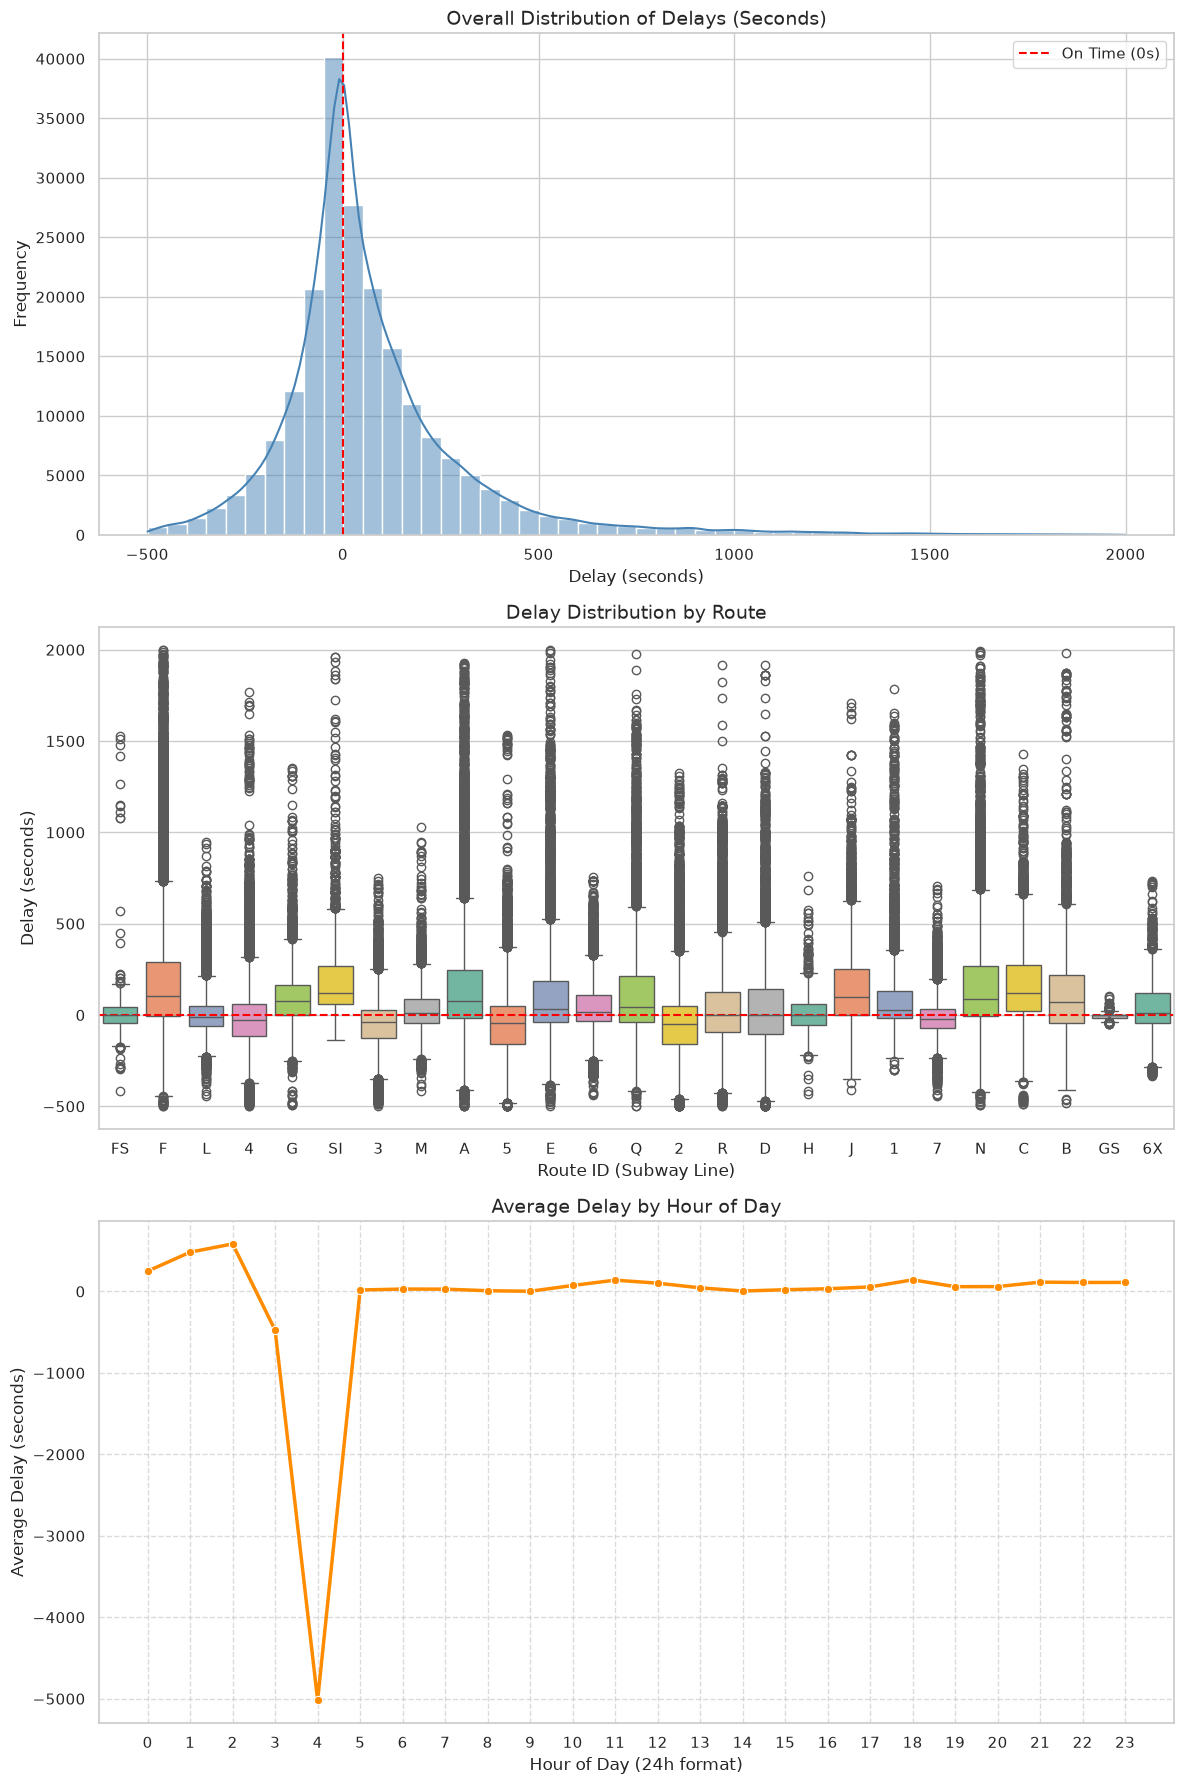

In [36]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Ensure event_time is a datetime object for time-based plotting
df['event_time'] = pd.to_datetime(df['event_time'])

# Extract the hour for time-of-day analysis
df['hour'] = df['event_time'].dt.hour

# Set up the plotting style
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(3, 1, figsize=(12, 18))

# ---------------------------------------------------------
# Plot 1: Distribution of Delays (Histogram)
# ---------------------------------------------------------
# Limiting to delays between -500s and 2000s to filter out extreme outliers
delay_mask = (df['delay_s'] > -500) & (df['delay_s'] < 2000)
sns.histplot(df[delay_mask]['delay_s'], bins=50, kde=True, ax=axes[0], color="steelblue")
axes[0].set_title('Overall Distribution of Delays (Seconds)', fontsize=14)
axes[0].set_xlabel('Delay (seconds)')
axes[0].set_ylabel('Frequency')
axes[0].axvline(0, color='red', linestyle='--', label='On Time (0s)')
axes[0].legend()

# ---------------------------------------------------------
# Plot 2: Delay Distribution by Route (Boxplot)
# ---------------------------------------------------------
# Boxplot shows the median and spread of delays for each subway line
sns.boxplot(
    x='route_id',
    y='delay_s',
    data=df[delay_mask],
    ax=axes[1],
    palette="Set2"
)
axes[1].set_title('Delay Distribution by Route', fontsize=14)
axes[1].set_xlabel('Route ID (Subway Line)')
axes[1].set_ylabel('Delay (seconds)')
axes[1].axhline(0, color='red', linestyle='--')

# ---------------------------------------------------------
# Plot 3: Average Delay by Hour of the Day (Line Plot)
# ---------------------------------------------------------
# Calculate the mean delay for each hour across all routes
hourly_delay = df.groupby('hour')['delay_s'].mean().reset_index()

sns.lineplot(
    x='hour',
    y='delay_s',
    data=hourly_delay,
    ax=axes[2],
    marker='o',
    color="darkorange",
    linewidth=2.5
)
axes[2].set_title('Average Delay by Hour of Day', fontsize=14)
axes[2].set_xlabel('Hour of Day (24h format)')
axes[2].set_ylabel('Average Delay (seconds)')
axes[2].set_xticks(range(0, 24))
axes[2].grid(True, linestyle='--', alpha=0.7)

# Adjust layout and display
plt.tight_layout()
plt.show()

In [37]:
# Isolate the 4 AM data
df_4am = df[df['hour'] == 4]

# 1. Check summary statistics to see if a few massive outliers are skewing the mean
print("--- 4 AM Delay Statistics ---")
print(df_4am['delay_s'].describe())

# 2. Sort by the most extreme negative delays
extreme_anomalies = df_4am.sort_values('delay_s').head(20)

# 3. Display relevant time columns to compare scheduled vs. actual times
cols_to_inspect = [
    'route_id', 'trip_id', 'stop_id',
    'sched_dep_sec', 'event_sec', 'delay_s', 'event_time'
]
print("\n--- Top 20 Most Extreme Early Arrivals at 4 AM ---")
print(extreme_anomalies[cols_to_inspect])

--- 4 AM Delay Statistics ---
count           14.0
mean    -5017.285714
std      6353.644931
min         -10501.0
25%         -10501.0
50%          -9856.0
75%          2137.25
max           2276.0
Name: delay_s, dtype: Float64

--- Top 20 Most Extreme Early Arrivals at 4 AM ---
       route_id      trip_id stop_id  sched_dep_sec     event_sec  delay_s  \
4223          F  034050_F..N    G08N   1704264930.0  1.704254e+09 -10501.0   
4224          F  034050_F..N    F07N   1704265050.0  1.704255e+09 -10501.0   
4225          F  034050_F..N    F06N   1704265140.0  1.704255e+09 -10501.0   
4226          F  034050_F..N    F05N   1704265260.0  1.704255e+09 -10501.0   
4227          F  034050_F..N    F04N   1704265350.0  1.704255e+09 -10501.0   
4228          F  034050_F..N    F03N   1704265470.0  1.704255e+09 -10291.0   
4229          F  034050_F..N    F02N   1704265620.0  1.704256e+09  -9931.0   
4230          F  034050_F..N    F01N   1704265740.0  1.704256e+09  -9781.0   
228034        F  0